# Notebook 07: Unseen City Validation & Variable-Horizon Demonstration

Validate zero-shot generalization on 5 completely unseen cities:
- Hyderabad, Bangalore, Kolkata, Lucknow, Jodhpur

Demonstrate the **HorizonPredictor** for variable-length forecasts
(24 hours to 365 days).

In [1]:
import sys, os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from pathlib import Path
from datetime import datetime, timedelta

sys.path.insert(0, os.path.abspath('.'))

from utils.city_config import (
    CITY_METADATA, get_test_cities, get_training_cities, get_all_cities,
    MODEL_CONFIG
)
from utils.metrics import compute_all_metrics, r2_score, mae, rmse
from utils.plotting import setup_plot_style, CITY_COLORS
from utils.normalization import RevIN
from utils.climatology import MultiCityClimatology

setup_plot_style()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")
os.makedirs('results/unseen_validation', exist_ok=True)
os.makedirs('results/figures', exist_ok=True)

Device: cuda


## 1. Load Models

In [3]:
# Load Chronos
from chronos import ChronosPipeline

model_name = 'amazon/chronos-t5-base'
pipeline = ChronosPipeline.from_pretrained(
    model_name,
    device_map=device,
    torch_dtype=torch.float16,
)
print(f"Chronos loaded on {device}")

# Load LoRA adapter if available
lora_path = 'models/chronos_lora'
has_lora = os.path.exists(os.path.join(lora_path, 'adapter_model.safetensors'))
if has_lora:
    from peft import PeftModel
    pipeline.model.model = PeftModel.from_pretrained(
        pipeline.model.model, lora_path
    )
    print("LoRA adapter loaded.")

# Load projection layers if saved
proj_path = os.path.join(lora_path, 'projections.pt')
if has_lora and os.path.exists(proj_path):
    d_model = pipeline.model.model.config.d_model
    input_proj = torch.nn.Linear(1, d_model).to(device)
    output_proj = torch.nn.Linear(d_model, 1).to(device)
    proj_state = torch.load(proj_path, map_location=device, weights_only=True)
    input_proj.load_state_dict(proj_state['input_projection'])
    output_proj.load_state_dict(proj_state['output_projection'])
    print("Projection layers loaded.")
else:
    input_proj, output_proj = None, None

# Load Climatological model
clim_path = 'models/climatology'
if os.path.exists(clim_path):
    multi_clim = MultiCityClimatology.load(clim_path)
    print(f"Climatological model loaded ({len(multi_clim.city_models)} cities)")
else:
    multi_clim = None
    print("No climatological model found.")

Chronos loaded on cuda
LoRA adapter loaded.
Projection layers loaded.
Climatological model loaded (7 cities)


## 2. Zero-Shot Evaluation on Unseen Cities

In [4]:
from tqdm.auto import tqdm

def chronos_predict_batched(pipeline, ghi_contexts, horizon=24, num_samples=20,
                            scales=[72, 48, 24], batch_size=16):
    """Batched multi-scale Chronos prediction with RevIN per sequence."""
    scale_preds = []
    for scale in scales:
        all_medians = []
        ctx_sub = ghi_contexts[:, -scale:] if ghi_contexts.shape[1] >= scale else ghi_contexts
        for start in tqdm(range(0, len(ctx_sub), batch_size), desc=f'scale={scale}h', leave=False):
            batch = ctx_sub[start:start+batch_size]
            # RevIN: per-sequence normalize
            means = batch.mean(axis=1, keepdims=True)
            stds = batch.std(axis=1, keepdims=True) + 1e-5
            batch_norm = (batch - means) / stds
            # CPU tensor for pipeline
            ctx_tensor = torch.tensor(batch_norm, dtype=torch.float32)
            with torch.no_grad():
                samples = pipeline.predict(ctx_tensor, prediction_length=horizon, num_samples=num_samples)
            samples_np = samples.cpu().numpy()
            # Denormalize
            samples_denorm = np.maximum(0, samples_np * stds[:, np.newaxis, :] + means[:, np.newaxis, :])
            all_medians.append(np.median(samples_denorm, axis=1))
        scale_preds.append(np.concatenate(all_medians, axis=0))
    return np.mean(scale_preds, axis=0)


# Evaluate on each test city
test_results = []

for city in get_test_cities():
    print(f"\n--- {city.title()} ---")
    info = CITY_METADATA[city]
    
    # Correct file names (plural: contexts / targets)
    ctx_path = f'data/processed/windows/{city}_test_contexts.npy'
    tgt_path = f'data/processed/windows/{city}_test_targets.npy'
    
    if not (os.path.exists(ctx_path) and os.path.exists(tgt_path)):
        print(f"  Windows not found. Run notebook 02 first.")
        continue
    
    contexts = np.load(ctx_path)
    targets = np.load(tgt_path)
    ghi_contexts = contexts[:, :, 0]  # Extract GHI channel (index 0)
    print(f"  Windows: {len(contexts)} | Context: {contexts.shape[1]}h | Target: {targets.shape[1]}h")
    
    preds = chronos_predict_batched(pipeline, ghi_contexts, horizon=24)
    
    # Metrics
    y_true = targets.flatten()
    y_pred = preds.flatten()[:len(y_true)]
    metrics = compute_all_metrics(y_true, y_pred)
    metrics['City'] = city.title()
    metrics['Climate'] = info['climate_zone']
    metrics['Role'] = 'Test'
    metrics['Model'] = 'Chronos-FT' if has_lora else 'Chronos-ZS'
    test_results.append(metrics)
    
    # Save predictions
    np.save(f'results/unseen_validation/pred_best_{city}.npy', preds)
    
    print(f"  R² = {metrics['R2']:.4f} | MAE = {metrics['MAE']:.2f} | RMSE = {metrics['RMSE']:.2f}")

test_df = pd.DataFrame(test_results)
display(test_df)


--- Hyderabad ---
  Windows: 729 | Context: 72h | Target: 24h


  R² = 0.9460 | MAE = 33.90 | RMSE = 66.41

--- Bangalore ---
  Windows: 729 | Context: 72h | Target: 24h


  R² = 0.9494 | MAE = 34.67 | RMSE = 66.91

--- Kolkata ---
  Windows: 729 | Context: 72h | Target: 24h


  R² = 0.9084 | MAE = 36.97 | RMSE = 76.06

--- Lucknow ---
  Windows: 729 | Context: 72h | Target: 24h


  R² = 0.9333 | MAE = 34.32 | RMSE = 69.67

--- Jodhpur ---
  Windows: 729 | Context: 72h | Target: 24h


  R² = 0.9589 | MAE = 29.55 | RMSE = 60.32


,MAE,RMSE,R2,SMAPE,MBE,N_samples,City,Climate,Role,Model
0,33.897873,66.414497,0.945959,101.482567,1.722994,17496,Hyderabad,BSh,Test,Chronos-FT
1,34.673054,66.909286,0.949433,103.344193,0.668590,17496,Bangalore,Aw,Test,Chronos-FT
2,36.972763,76.061737,0.908417,105.382599,3.535654,17496,Kolkata,Aw,Test,Chronos-FT
3,34.321167,69.667542,0.933344,105.501091,0.093654,17496,Lucknow,Cwa,Test,Chronos-FT
4,29.546597,60.316338,0.958912,99.284019,-2.018798,17496,Jodhpur,BWh,Test,Chronos-FT


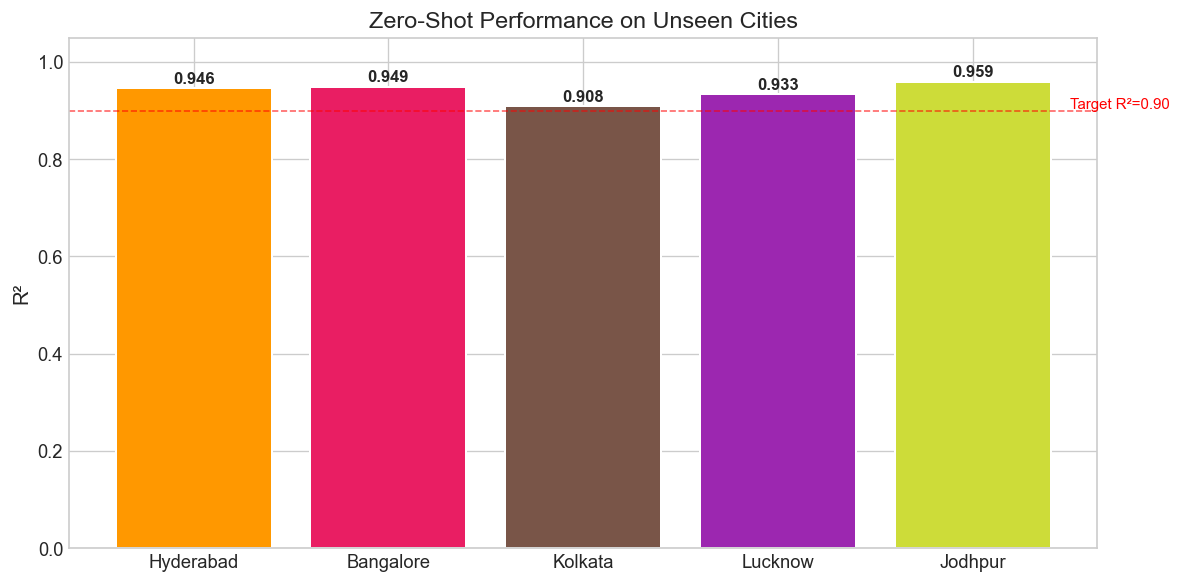

In [5]:
# Bar chart: R² per unseen city
if not test_df.empty:
    fig, ax = plt.subplots(figsize=(10, 5))
    bars = ax.bar(
        test_df['City'], test_df['R2'],
        color=[CITY_COLORS.get(c.lower(), '#666') for c in test_df['City']],
        edgecolor='white', linewidth=1.2
    )
    ax.axhline(0.90, color='red', linestyle='--', alpha=0.6, linewidth=1)
    ax.text(len(test_df)-0.5, 0.905, 'Target R²=0.90', color='red', fontsize=9)
    ax.set_ylabel('R²')
    ax.set_title('Zero-Shot Performance on Unseen Cities', fontsize=14)
    ax.set_ylim(0, 1.05)
    
    for bar, r2 in zip(bars, test_df['R2']):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{r2:.3f}', ha='center', fontsize=10, fontweight='bold')
    
    plt.tight_layout()
    plt.savefig('results/figures/07_unseen_r2.png', dpi=300, bbox_inches='tight')
    plt.show()

## 3. Variable-Horizon Demonstration

In [6]:
from utils.horizon_engine import HorizonPredictor, get_horizon_label, get_method_for_horizon

# Initialize — correct kwargs: chronos_pipeline + climatology (no device param)
hp = HorizonPredictor(
    chronos_pipeline=pipeline,
    climatology=multi_clim,
)

# Demo city: first unseen test city
demo_city = get_test_cities()[0]
demo_info = CITY_METADATA[demo_city]

# Load recent context (last available 72 hours) — GHI channel (index 0)
ctx_path = f'data/processed/windows/{demo_city}_test_contexts.npy'
if os.path.exists(ctx_path):
    contexts = np.load(ctx_path)
    demo_context = contexts[-1, :, 0]  # Last window, GHI channel
else:
    print("No context data. Using synthetic.")
    demo_context = np.zeros(72)

print(f"Demo city: {demo_city.title()} ({demo_info['latitude']:.1f}°N, {demo_info['longitude']:.1f}°E)")
print(f"Context length: {len(demo_context)} hours")

Demo city: Hyderabad (17.4°N, 78.5°E)
Context length: 72 hours


Predicting 1d (24h) — Method: Chronos (pure)
Predicting 3d (72h) — Method: Chronos (pure)
Predicting 7d (168h) — Method: Chronos + Climatology (blended)
Predicting 14d (336h) — Method: Chronos + Climatology (blended)
Predicting 30d (720h) — Method: Climatological model
Predicting 90d (2160h) — Method: Climatological model
Predicting 365d (8760h) — Method: Climatological model


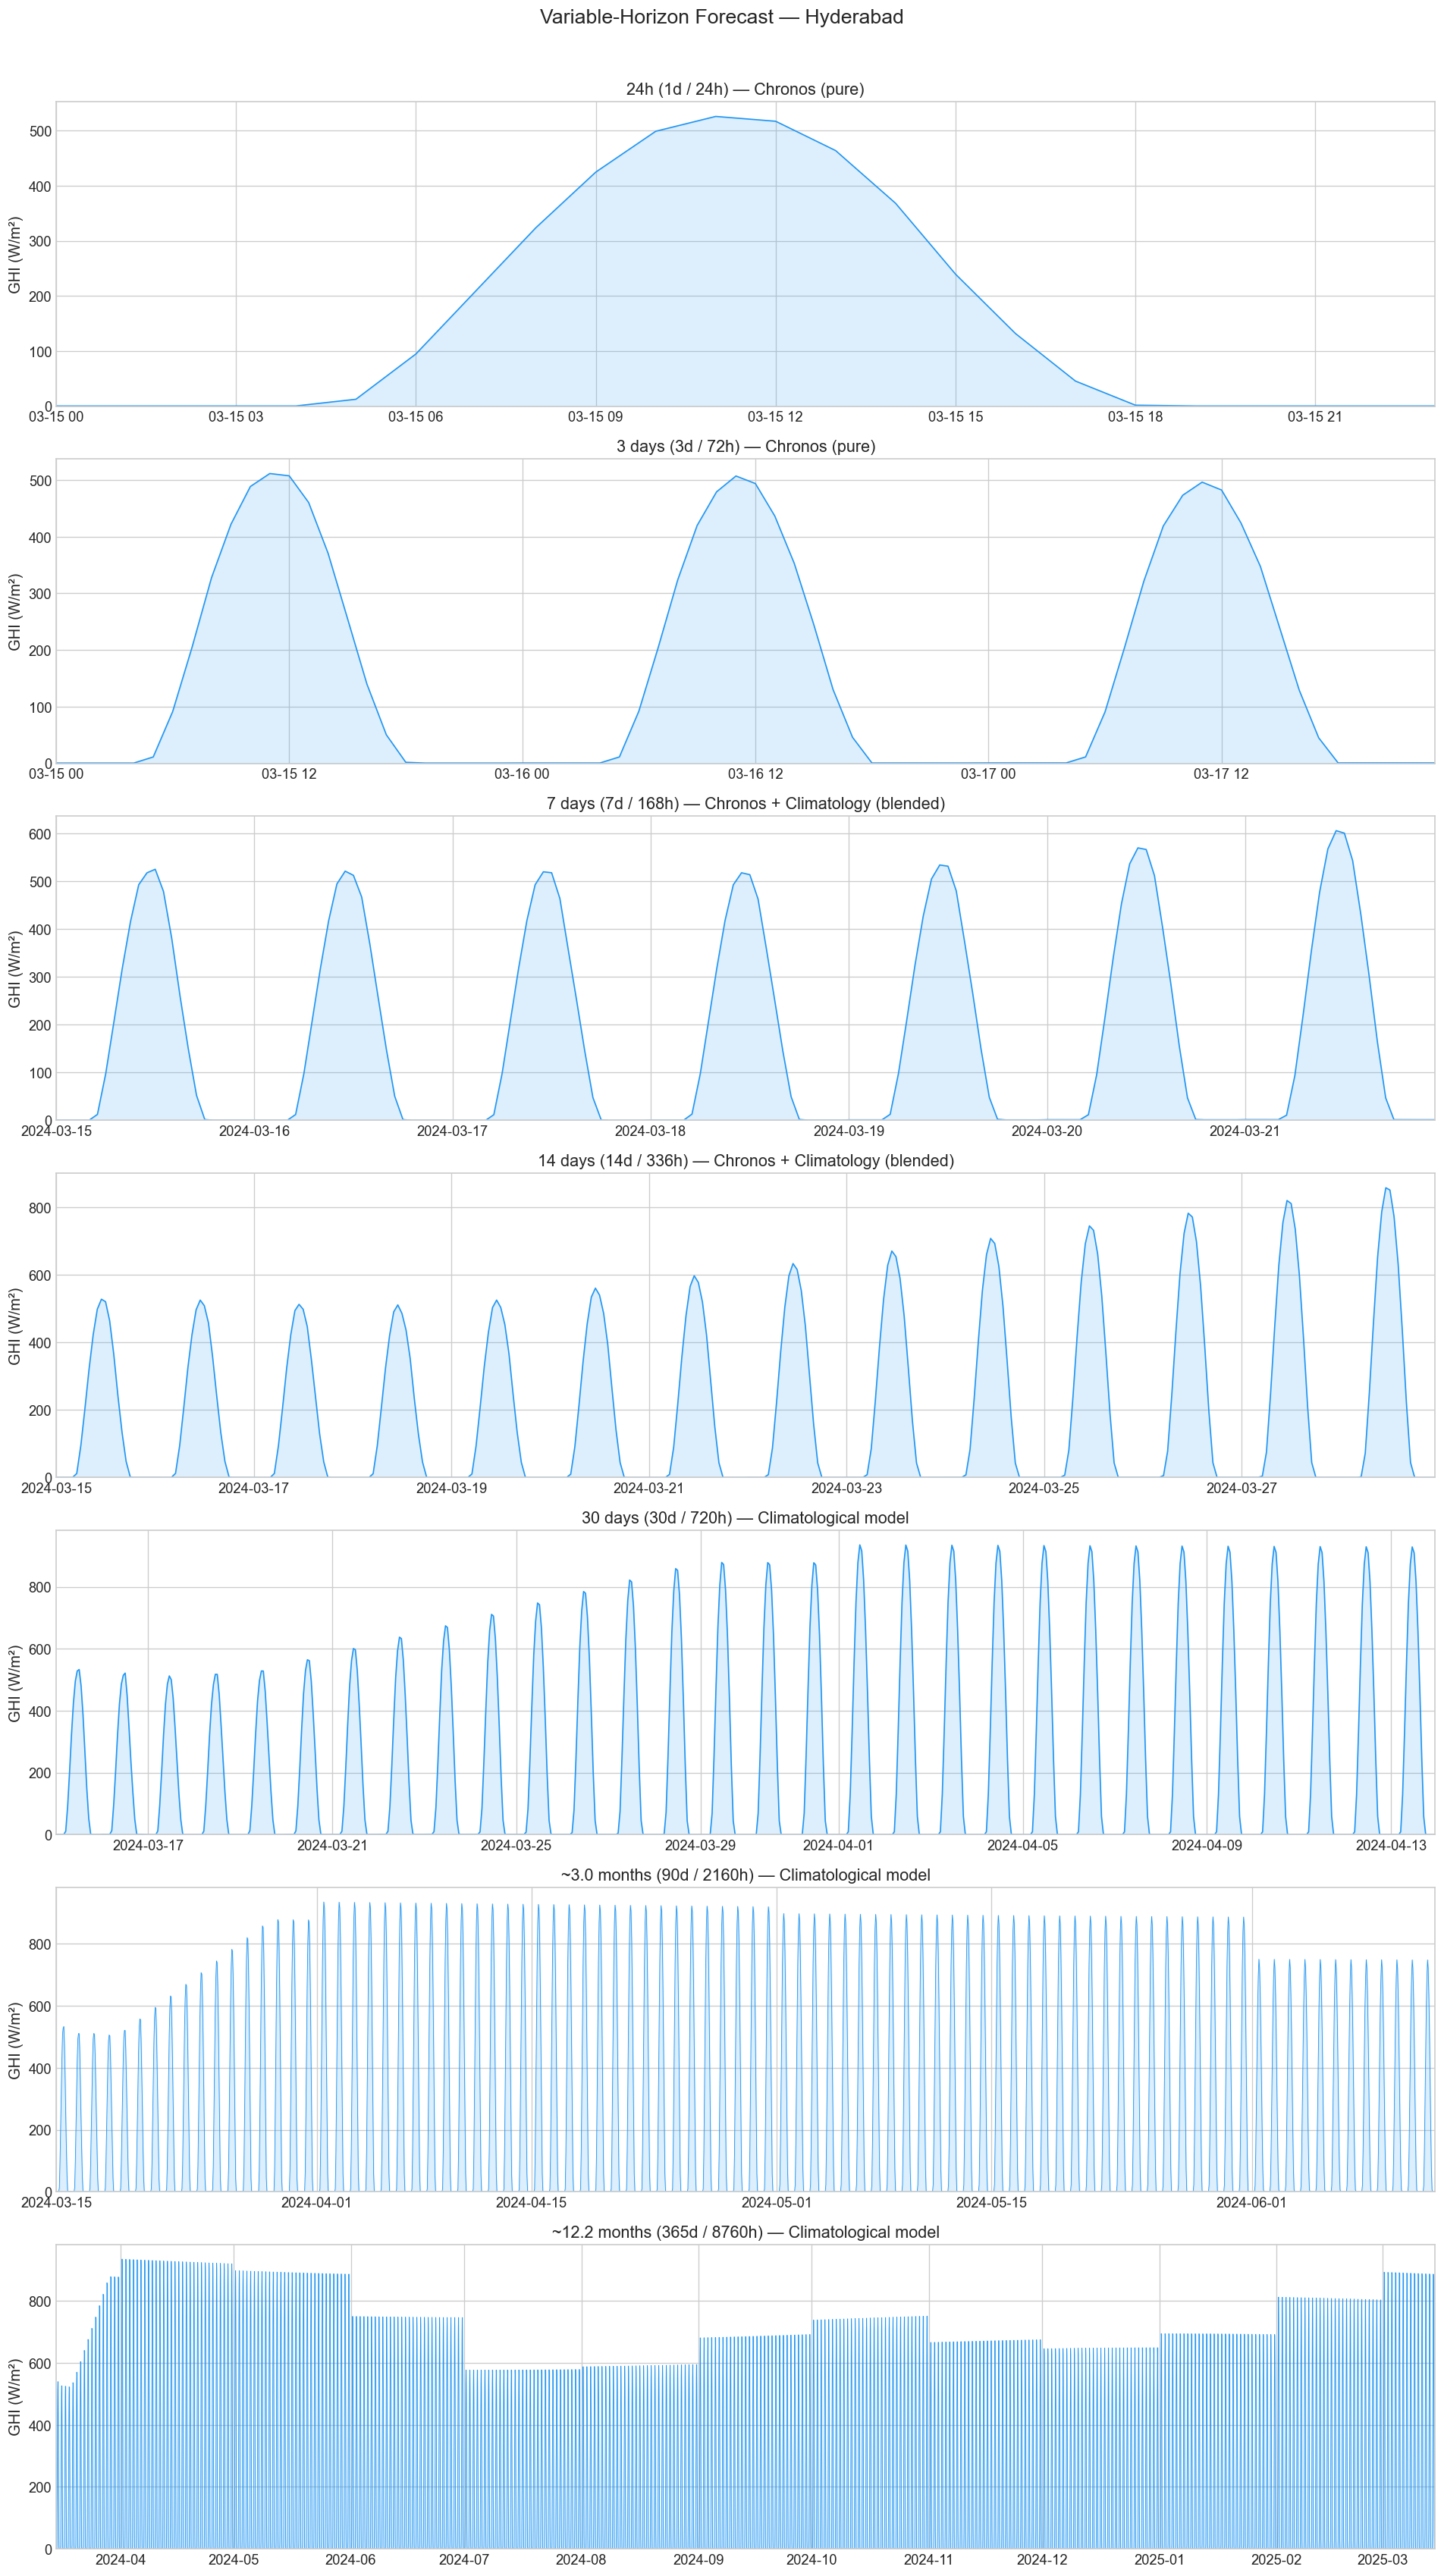

In [7]:
# Variable-horizon predictions
horizons_days = [1, 3, 7, 14, 30, 90, 365]
demo_date = pd.Timestamp('2024-03-15')  # A spring equinox date

fig, axes = plt.subplots(len(horizons_days), 1, figsize=(16, 4*len(horizons_days)))

for ax, days in zip(axes, horizons_days):
    hours = days * 24
    # Module-level functions (not instance methods)
    label = get_horizon_label(hours)
    method = get_method_for_horizon(hours)
    
    print(f"Predicting {days}d ({hours}h) — Method: {method}")
    
    result = hp.predict(
        context=demo_context,
        horizon_hours=hours,
        latitude=demo_info['latitude'],
        longitude=demo_info['longitude'],
        start_date=demo_date,
        city_name=demo_city,
    )
    # predict() returns a dict; use the 'mean' key
    prediction = result['mean']
    
    time_axis = pd.date_range(demo_date, periods=hours, freq='h')
    ax.plot(time_axis, prediction, color='#2196F3', linewidth=0.5 if days > 30 else 1)
    ax.fill_between(time_axis, 0, prediction, alpha=0.15, color='#2196F3')
    ax.set_ylabel('GHI (W/m²)')
    ax.set_title(f'{label} ({days}d / {hours}h) — {method}')
    ax.set_xlim(time_axis[0], time_axis[-1])
    ax.set_ylim(0, None)

plt.suptitle(f'Variable-Horizon Forecast — {demo_city.title()}', fontsize=16, y=1.01)
plt.tight_layout()
plt.savefig('results/figures/07_variable_horizon.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Climate Zone Transfer Analysis

In [8]:
# How well does each training climate zone transfer to unseen test cities?
train_climates = set(CITY_METADATA[c]['climate_zone'] for c in get_training_cities())
test_climates = set(CITY_METADATA[c]['climate_zone'] for c in get_test_cities())

print("Training climate zones:", sorted(train_climates))
print("Test climate zones:    ", sorted(test_climates))
print("Overlap:               ", sorted(train_climates & test_climates))
print("Unseen climates:       ", sorted(test_climates - train_climates))

if not test_df.empty:
    # Group by climate
    climate_perf = test_df.groupby('Climate')['R2'].agg(['mean', 'min', 'max', 'count'])
    print("\nR² by Climate Zone (Test Cities):")
    display(climate_perf)

Training climate zones: ['Am', 'Aw', 'BSh', 'BWh', 'Cwa']
Test climate zones:     ['Aw', 'BSh', 'BWh', 'Cwa']
Overlap:                ['Aw', 'BSh', 'BWh', 'Cwa']
Unseen climates:        []

R² by Climate Zone (Test Cities):


,mean,min,max,count
Climate,,,,
Aw,0.928925,0.908417,0.949433,2
BSh,0.945959,0.945959,0.945959,1
BWh,0.958912,0.958912,0.958912,1
Cwa,0.933344,0.933344,0.933344,1


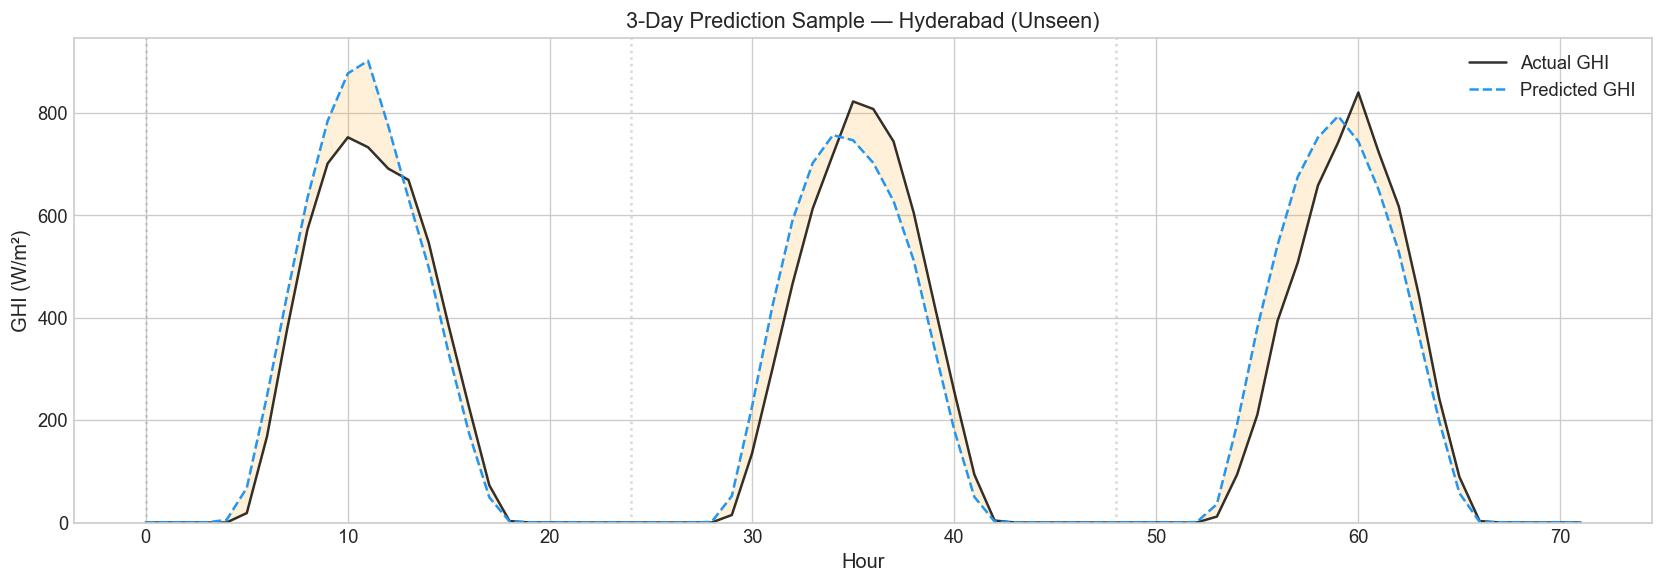

In [9]:
# Prediction sample: time-series overlay for 3 days
if os.path.exists(f'data/processed/windows/{demo_city}_test_targets.npy'):
    targets = np.load(f'data/processed/windows/{demo_city}_test_targets.npy')
    preds = np.load(f'results/unseen_validation/pred_best_{demo_city}.npy')
    
    # Show 3 consecutive days
    fig, ax = plt.subplots(figsize=(14, 5))
    start_idx = len(targets) // 2  # Middle of test period
    n_windows = 3
    
    all_tgt = np.concatenate([targets[start_idx + i] for i in range(n_windows)])
    all_pred = np.concatenate([preds[start_idx + i] for i in range(n_windows)])
    hours = np.arange(len(all_tgt))
    
    ax.plot(hours, all_tgt, 'k-', linewidth=1.5, label='Actual GHI', alpha=0.8)
    ax.plot(hours, all_pred, '--', color='#2196F3', linewidth=1.5, label='Predicted GHI')
    ax.fill_between(hours, all_tgt, all_pred, alpha=0.15, color='orange')
    
    for d in range(n_windows):
        ax.axvline(d * 24, color='gray', linestyle=':', alpha=0.3)
    
    ax.set_xlabel('Hour')
    ax.set_ylabel('GHI (W/m²)')
    ax.set_title(f'3-Day Prediction Sample — {demo_city.title()} (Unseen)')
    ax.legend()
    ax.set_ylim(0, None)
    
    plt.tight_layout()
    plt.savefig('results/figures/07_prediction_sample.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print("Prediction files not yet available.")

In [10]:
# Save final unseen results
if not test_df.empty:
    test_df.to_csv('results/unseen_validation/unseen_results.csv', index=False)
    
    summary = {
        'n_test_cities': len(test_df),
        'avg_r2': float(test_df['R2'].mean()),
        'min_r2': float(test_df['R2'].min()),
        'max_r2': float(test_df['R2'].max()),
        'avg_mae': float(test_df['MAE'].mean()),
        'cities_above_090': int((test_df['R2'] >= 0.90).sum()),
        'model_used': 'Chronos-FT' if has_lora else 'Chronos-ZS',
        'timestamp': datetime.now().isoformat()
    }
    with open('results/unseen_validation/unseen_summary.json', 'w') as f:
        json.dump(summary, f, indent=2)
    
    print("\n" + "="*60)
    print(f" UNSEEN CITY VALIDATION SUMMARY")
    print("="*60)
    print(f" Average R²   : {summary['avg_r2']:.4f}")
    print(f" Min R²       : {summary['min_r2']:.4f}")
    print(f" Max R²       : {summary['max_r2']:.4f}")
    print(f" Cities ≥ 0.90: {summary['cities_above_090']} / {summary['n_test_cities']}")
    print("="*60)


 UNSEEN CITY VALIDATION SUMMARY
 Average R²   : 0.9392
 Min R²       : 0.9084
 Max R²       : 0.9589
 Cities ≥ 0.90: 5 / 5


## Summary

Validated zero-shot / fine-tuned Chronos on **5 completely unseen** Indian cities.

Demonstrated variable-horizon prediction from **24h to 1 year**.

**Next →** `streamlit_app.py` — Interactive demo application